In [1]:
# VERIFICACION DE GPU E INSTALACION DE DEPENDENCIAS
!nvidia-smi
!pip -q install transformers datasets evaluate accelerate huggingface_hub timm scikit-learn pandas matplotlib seaborn

Mon Oct 12 01:58:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# IMPORTACION DE LIBRERIAS Y CONFIGURACION INICIAL
import os
import time
import platform
import numpy as np
import pandas as pd
import torch
import evaluate
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import userdata
from huggingface_hub import login, whoami

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"GPU disponible: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU asignada: {torch.cuda.get_device_name(0)}")

HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError("No se encontró el secreto HF_TOKEN en Colab.")

login(token=HF_TOKEN, add_to_git_credential=False)
print(f"Autenticado en Hugging Face como: {whoami()['name']}")

Python: 3.13.15
PyTorch: 2.11.0+cu130
GPU disponible: True
GPU asignada: Tesla T4
Autenticado en Hugging Face como: Ecovarrubias


In [3]:
# DESCARGA Y PREPARACION DEL DATASET
from pathlib import Path
from zipfile import ZipFile
from huggingface_hub import hf_hub_download
from datasets import Dataset, DatasetDict, Image as HFImage
from collections import Counter

REPO_DATASET = "2OBe/Ball_Screw_Drive_Classification"
CARPETA_BASE = Path("/content/ball_screw_defects")
CARPETA_BASE.mkdir(parents=True, exist_ok=True)

MAPA_DIVISIONES = {
    "train": "train",
    "valid": "validation",
    "test": "test"
}

for archivo_zip, division_final in MAPA_DIVISIONES.items():
    carpeta_destino = CARPETA_BASE / division_final
    carpeta_destino.mkdir(parents=True, exist_ok=True)

    ruta_zip = hf_hub_download(
        repo_id=REPO_DATASET,
        repo_type="dataset",
        filename=f"{archivo_zip}.zip"
    )

    with ZipFile(ruta_zip, "r") as archivo_comprimido:
        archivo_comprimido.extractall(carpeta_destino)

    print(f"Extraído: {archivo_zip}.zip")

def obtener_etiqueta(ruta_imagen):
    partes = [parte.upper() for parte in ruta_imagen.parts]

    if "N" in partes or ruta_imagen.name.upper().startswith("N"):
        return 0

    if "P" in partes or ruta_imagen.name.upper().startswith("P"):
        return 1

    return None

extensiones_imagen = {".jpg", ".jpeg", ".png", ".bmp"}
divisiones_dataset = {}

for division in MAPA_DIVISIONES.values():
    archivos = [
        ruta for ruta in (CARPETA_BASE / division).rglob("*")
        if ruta.suffix.lower() in extensiones_imagen
    ]

    rutas_validas = []
    etiquetas = []

    for ruta in archivos:
        etiqueta = obtener_etiqueta(ruta)

        if etiqueta is not None:
            rutas_validas.append(str(ruta))
            etiquetas.append(etiqueta)

    divisiones_dataset[division] = Dataset.from_dict({
        "image": rutas_validas,
        "label": etiquetas
    }).cast_column("image", HFImage())

    conteo = Counter(etiquetas)
    print(
        f"{division.upper()}: {len(etiquetas)} imágenes | "
        f"OK: {conteo[0]} | Defecto: {conteo[1]}"
    )

dataset_procesado = DatasetDict(divisiones_dataset)
dataset_procesado

train.zip: reconstructing file:   0%|          |  0.00B /  486MB            

train.zip: downloading bytes:           |  0.00B            

Extraído: train.zip


valid.zip: reconstructing file:   0%|          |  0.00B /  133MB            

valid.zip: downloading bytes:           |  0.00B            

Extraído: valid.zip


test.zip: reconstructing file:   0%|          |  0.00B / 67.2MB            

test.zip: downloading bytes:           |  0.00B            

Extraído: test.zip
TRAIN: 15709 imágenes | OK: 7962 | Defecto: 7747
VALIDATION: 4100 imágenes | OK: 2061 | Defecto: 2039
TEST: 2026 imágenes | OK: 1052 | Defecto: 974


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 15709
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 4100
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 2026
    })
})

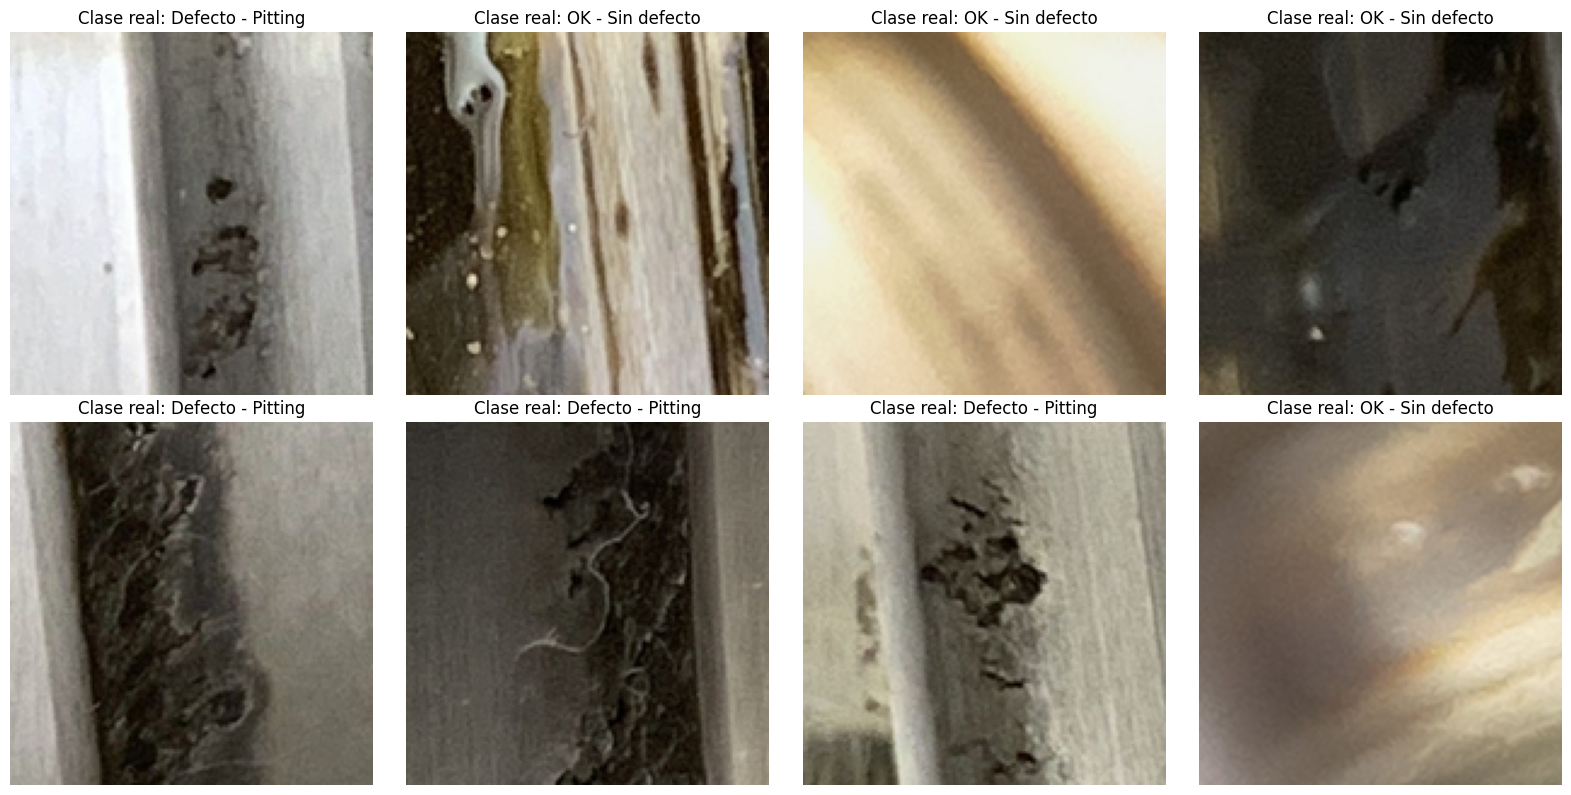

In [4]:
# VISUALIZACION DE EJEMPLOS DEL DATASET
NOMBRES_CLASE = {
    0: "OK - Sin defecto",
    1: "Defecto - Pitting"
}

generador = np.random.default_rng(42)
indices = generador.choice(
    len(dataset_procesado["train"]),
    size=8,
    replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for indice, eje in zip(indices, axes.flat):
    ejemplo = dataset_procesado["train"][int(indice)]

    eje.imshow(ejemplo["image"])
    eje.set_title(f"Clase real: {NOMBRES_CLASE[ejemplo['label']]}")
    eje.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# CREACION DE MUESTRA BALANCEADA PARA ENTRENAMIENTO
from datasets import concatenate_datasets

def crear_muestra_balanceada(datos, imagenes_por_clase, semilla):
    clase_ok = (
        datos
        .filter(lambda registro: registro["label"] == 0)
        .shuffle(seed=semilla)
        .select(range(imagenes_por_clase))
    )

    clase_defecto = (
        datos
        .filter(lambda registro: registro["label"] == 1)
        .shuffle(seed=semilla)
        .select(range(imagenes_por_clase))
    )

    return concatenate_datasets([clase_ok, clase_defecto]).shuffle(seed=semilla)

dataset_modelado = DatasetDict({
    "train": crear_muestra_balanceada(
        dataset_procesado["train"],
        imagenes_por_clase=1500,
        semilla=42
    ),
    "validation": crear_muestra_balanceada(
        dataset_procesado["validation"],
        imagenes_por_clase=300,
        semilla=42
    ),
    "test": crear_muestra_balanceada(
        dataset_procesado["test"],
        imagenes_por_clase=500,
        semilla=42
    )
})

for division, datos in dataset_modelado.items():
    conteo = Counter(datos["label"])
    print(
        f"{division.upper()}: {len(datos)} imágenes | "
        f"OK: {conteo[0]} | Defecto: {conteo[1]}"
    )

Filter:   0%|          | 0/15709 [00:00<?, ? examples/s]

Filter:   0%|          | 0/15709 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4100 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4100 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2026 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2026 [00:00<?, ? examples/s]

TRAIN: 3000 imágenes | OK: 1500 | Defecto: 1500
VALIDATION: 600 imágenes | OK: 300 | Defecto: 300
TEST: 1000 imágenes | OK: 500 | Defecto: 500


In [6]:
# CONFIGURACION COMUN PARA ENTRENAMIENTO Y EVALUACION
from torchvision.transforms import (
    Compose,
    RandomResizedCrop,
    RandomHorizontalFlip,
    Resize,
    CenterCrop,
    ToTensor,
    Normalize
)

from torch.utils.data import DataLoader
from transformers import AutoImageProcessor, ResNetForImageClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim import AdamW
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ID_MODELO_RESNET = "microsoft/resnet-50"
procesador_resnet = AutoImageProcessor.from_pretrained(ID_MODELO_RESNET)

media = procesador_resnet.image_mean
desviacion = procesador_resnet.image_std

transformacion_entrenamiento = Compose([
    RandomResizedCrop(224),
    RandomHorizontalFlip(),
    ToTensor(),
    Normalize(mean=media, std=desviacion)
])

transformacion_evaluacion = Compose([
    Resize(256),
    CenterCrop(224),
    ToTensor(),
    Normalize(mean=media, std=desviacion)
])

def aplicar_transformacion_entrenamiento(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_entrenamiento(imagen)
        for imagen in imagenes
    ]
    return lote

def aplicar_transformacion_evaluacion(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_evaluacion(imagen)
        for imagen in imagenes
    ]
    return lote

def agrupar_lote(ejemplos):
    return {
        "pixel_values": torch.stack(
            [ejemplo["pixel_values"] for ejemplo in ejemplos]
        ),
        "labels": torch.tensor(
            [ejemplo["label"] for ejemplo in ejemplos],
            dtype=torch.long
        )
    }

def calcular_metricas(etiquetas_reales, predicciones):
    precision, recall, f1, _ = precision_recall_fscore_support(
        etiquetas_reales,
        predicciones,
        average="binary",
        pos_label=1,
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(etiquetas_reales, predicciones),
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }

def evaluar_modelo(modelo, cargador):
    modelo.eval()
    etiquetas_reales = []
    predicciones = []

    with torch.no_grad():
        for lote in cargador:
            pixeles = lote["pixel_values"].to(dispositivo)
            etiquetas = lote["labels"].to(dispositivo)

            salida = modelo(pixel_values=pixeles)
            prediccion = torch.argmax(salida.logits, dim=1)

            etiquetas_reales.extend(etiquetas.cpu().numpy())
            predicciones.extend(prediccion.cpu().numpy())

    return calcular_metricas(etiquetas_reales, predicciones)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

In [7]:
# MODELO 1 RESNET 50 PREENTRENADO EN IMAGENET
entrenamiento_resnet = dataset_modelado["train"].with_transform(
    aplicar_transformacion_entrenamiento
)

validacion_resnet = dataset_modelado["validation"].with_transform(
    aplicar_transformacion_evaluacion
)

cargador_entrenamiento = DataLoader(
    entrenamiento_resnet,
    batch_size=32,
    shuffle=True,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

cargador_validacion = DataLoader(
    validacion_resnet,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

modelo_resnet = ResNetForImageClassification.from_pretrained(
    ID_MODELO_RESNET,
    num_labels=2,
    ignore_mismatched_sizes=True,
    id2label={0: "OK", 1: "Defecto"},
    label2id={"OK": 0, "Defecto": 1}
).to(dispositivo)

optimizador = AdamW(modelo_resnet.parameters(), lr=2e-5)
EPOCAS = 2

historial_resnet = []

for epoca in range(EPOCAS):
    modelo_resnet.train()
    perdida_acumulada = 0

    barra = tqdm(
        cargador_entrenamiento,
        desc=f"ResNet-50 | Época {epoca + 1}/{EPOCAS}"
    )

    for lote in barra:
        pixeles = lote["pixel_values"].to(dispositivo)
        etiquetas = lote["labels"].to(dispositivo)

        optimizador.zero_grad()

        salida = modelo_resnet(
            pixel_values=pixeles,
            labels=etiquetas
        )

        perdida = salida.loss
        perdida.backward()
        optimizador.step()

        perdida_acumulada += perdida.item()
        barra.set_postfix(loss=f"{perdida.item():.4f}")

    metricas_validacion = evaluar_modelo(
        modelo_resnet,
        cargador_validacion
    )

    resultado_epoca = {
        "epoca": epoca + 1,
        "loss_entrenamiento": perdida_acumulada / len(cargador_entrenamiento),
        **metricas_validacion
    }

    historial_resnet.append(resultado_epoca)

    print(
        f"\nÉpoca {epoca + 1} | "
        f"Loss: {resultado_epoca['loss_entrenamiento']:.4f} | "
        f"Accuracy: {resultado_epoca['accuracy']:.4f} | "
        f"Precision: {resultado_epoca['precision']:.4f} | "
        f"Recall: {resultado_epoca['recall']:.4f} | "
        f"F1-score: {resultado_epoca['f1_score']:.4f}"
    )

tabla_historial_resnet = pd.DataFrame(historial_resnet)
tabla_historial_resnet

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

...

ResNet-50 | Época 1/2:   0%|          | 0/94 [00:00<?, ?it/s]


Época 1 | Loss: 0.6869 | Accuracy: 0.7400 | Precision: 0.7105 | Recall: 0.8100 | F1-score: 0.7570


ResNet-50 | Época 2/2:   0%|          | 0/94 [00:00<?, ?it/s]


Época 2 | Loss: 0.6706 | Accuracy: 0.8000 | Precision: 0.7778 | Recall: 0.8400 | F1-score: 0.8077


,epoca,loss_entrenamiento,accuracy,precision,recall,f1_score
0,1,0.686923,0.74,0.710526,0.81,0.757009
1,2,0.670557,0.80,0.777778,0.84,0.807692


In [8]:
# EVALUACION FINAL Y LATENCIA DE RESNET 50
from transformers import pipeline

prueba_resnet = dataset_modelado["test"].with_transform(
    aplicar_transformacion_evaluacion
)

cargador_prueba = DataLoader(
    prueba_resnet,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

metricas_resnet_prueba = evaluar_modelo(
    modelo_resnet,
    cargador_prueba
)

print("Métricas finales de ResNet-50 en el conjunto de prueba:")
for nombre, valor in metricas_resnet_prueba.items():
    print(f"{nombre}: {valor:.4f}")

# Medición de latencia individual con 100 imágenes del conjunto de prueba
muestra_latencia = prueba_resnet.select(range(100))
cargador_latencia = DataLoader(
    muestra_latencia,
    batch_size=1,
    shuffle=False,
    collate_fn=agrupar_lote
)

modelo_resnet.eval()

with torch.no_grad():
    lote_calentamiento = next(iter(cargador_latencia))
    _ = modelo_resnet(
        pixel_values=lote_calentamiento["pixel_values"].to(dispositivo)
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

tiempos_ms = []

with torch.no_grad():
    for lote in cargador_latencia:
        pixeles = lote["pixel_values"].to(dispositivo)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inicio = time.perf_counter()
        _ = modelo_resnet(pixel_values=pixeles)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        tiempos_ms.append((time.perf_counter() - inicio) * 1000)

latencia_promedio_resnet = float(np.mean(tiempos_ms))
latencia_desviacion_resnet = float(np.std(tiempos_ms))

print(f"\nLatencia promedio: {latencia_promedio_resnet:.2f} ms por imagen")
print(f"Desviación estándar: {latencia_desviacion_resnet:.2f} ms")

# Pipeline de inferencia
pipeline_resnet = pipeline(
    task="image-classification",
    model=modelo_resnet,
    image_processor=procesador_resnet,
    device=0 if torch.cuda.is_available() else -1
)

ejemplo_pipeline = dataset_modelado["test"][0]["image"].convert("RGB")

print("\nEjemplo de inferencia con pipeline:")
print(pipeline_resnet(ejemplo_pipeline, top_k=2))

resultados_modelos = [{
    "modelo": "ResNet-50",
    "arquitectura": "CNN residual",
    "parametros_millones": 25.6,
    "accuracy": metricas_resnet_prueba["accuracy"],
    "precision": metricas_resnet_prueba["precision"],
    "recall": metricas_resnet_prueba["recall"],
    "f1_score": metricas_resnet_prueba["f1_score"],
    "latencia_ms": latencia_promedio_resnet
}]

Métricas finales de ResNet-50 en el conjunto de prueba:
accuracy: 0.7060
precision: 0.6630
recall: 0.8380
f1_score: 0.7403

Latencia promedio: 7.25 ms por imagen
Desviación estándar: 1.06 ms

Ejemplo de inferencia con pipeline:
[{'label': 'Defecto', 'score': 0.5323902368545532}, {'label': 'OK', 'score': 0.4676097631454468}]


In [9]:
# MODELO 2 CONVNEXT TINY PREENTRENADO EN IMAGENET
from transformers import ConvNextForImageClassification

ID_MODELO_CONVNEXT = "facebook/convnext-tiny-224"
procesador_convnext = AutoImageProcessor.from_pretrained(
    ID_MODELO_CONVNEXT
)

media_convnext = procesador_convnext.image_mean
desviacion_convnext = procesador_convnext.image_std

transformacion_entrenamiento_convnext = Compose([
    RandomResizedCrop(224),
    RandomHorizontalFlip(),
    ToTensor(),
    Normalize(mean=media_convnext, std=desviacion_convnext)
])

transformacion_evaluacion_convnext = Compose([
    Resize(256),
    CenterCrop(224),
    ToTensor(),
    Normalize(mean=media_convnext, std=desviacion_convnext)
])

def aplicar_transformacion_entrenamiento_convnext(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_entrenamiento_convnext(imagen)
        for imagen in imagenes
    ]
    return lote

def aplicar_transformacion_evaluacion_convnext(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_evaluacion_convnext(imagen)
        for imagen in imagenes
    ]
    return lote

entrenamiento_convnext = dataset_modelado["train"].with_transform(
    aplicar_transformacion_entrenamiento_convnext
)

validacion_convnext = dataset_modelado["validation"].with_transform(
    aplicar_transformacion_evaluacion_convnext
)

cargador_entrenamiento_convnext = DataLoader(
    entrenamiento_convnext,
    batch_size=32,
    shuffle=True,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

cargador_validacion_convnext = DataLoader(
    validacion_convnext,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

modelo_convnext = ConvNextForImageClassification.from_pretrained(
    ID_MODELO_CONVNEXT,
    num_labels=2,
    ignore_mismatched_sizes=True,
    id2label={0: "OK", 1: "Defecto"},
    label2id={"OK": 0, "Defecto": 1}
).to(dispositivo)

optimizador_convnext = AdamW(
    modelo_convnext.parameters(),
    lr=2e-5
)

historial_convnext = []

for epoca in range(EPOCAS):
    modelo_convnext.train()
    perdida_acumulada = 0

    barra = tqdm(
        cargador_entrenamiento_convnext,
        desc=f"ConvNeXt-Tiny | Época {epoca + 1}/{EPOCAS}"
    )

    for lote in barra:
        pixeles = lote["pixel_values"].to(dispositivo)
        etiquetas = lote["labels"].to(dispositivo)

        optimizador_convnext.zero_grad()

        salida = modelo_convnext(
            pixel_values=pixeles,
            labels=etiquetas
        )

        perdida = salida.loss
        perdida.backward()
        optimizador_convnext.step()

        perdida_acumulada += perdida.item()
        barra.set_postfix(loss=f"{perdida.item():.4f}")

    metricas_validacion = evaluar_modelo(
        modelo_convnext,
        cargador_validacion_convnext
    )

    resultado_epoca = {
        "epoca": epoca + 1,
        "loss_entrenamiento": perdida_acumulada / len(
            cargador_entrenamiento_convnext
        ),
        **metricas_validacion
    }

    historial_convnext.append(resultado_epoca)

    print(
        f"\nÉpoca {epoca + 1} | "
        f"Loss: {resultado_epoca['loss_entrenamiento']:.4f} | "
        f"Accuracy: {resultado_epoca['accuracy']:.4f} | "
        f"Precision: {resultado_epoca['precision']:.4f} | "
        f"Recall: {resultado_epoca['recall']:.4f} | "
        f"F1-score: {resultado_epoca['f1_score']:.4f}"
    )

tabla_historial_convnext = pd.DataFrame(historial_convnext)
tabla_historial_convnext

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  114MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            


Época 1 | Loss: 0.4572 | Accuracy: 0.9583 | Precision: 0.9231 | Recall: 1.0000 | F1-score: 0.9600


ConvNeXt-Tiny | Época 2/2:   0%|          | 0/94 [00:00<?, ?it/s]


Época 2 | Loss: 0.2132 | Accuracy: 0.9817 | Precision: 0.9676 | Recall: 0.9967 | F1-score: 0.9819


,epoca,loss_entrenamiento,accuracy,precision,recall,f1_score
0,1,0.457177,0.958333,0.923077,1.000000,0.960000
1,2,0.213155,0.981667,0.967638,0.996667,0.981938


In [10]:
# EVALUACION FINAL Y LATENCIA DE CONVNEXT TINY
prueba_convnext = dataset_modelado["test"].with_transform(
    aplicar_transformacion_evaluacion_convnext
)

cargador_prueba_convnext = DataLoader(
    prueba_convnext,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

metricas_convnext_prueba = evaluar_modelo(
    modelo_convnext,
    cargador_prueba_convnext
)

print("Métricas finales de ConvNeXt-Tiny en el conjunto de prueba:")
for nombre, valor in metricas_convnext_prueba.items():
    print(f"{nombre}: {valor:.4f}")

muestra_latencia_convnext = prueba_convnext.select(range(100))

cargador_latencia_convnext = DataLoader(
    muestra_latencia_convnext,
    batch_size=1,
    shuffle=False,
    collate_fn=agrupar_lote
)

modelo_convnext.eval()

with torch.no_grad():
    lote_calentamiento = next(iter(cargador_latencia_convnext))
    _ = modelo_convnext(
        pixel_values=lote_calentamiento["pixel_values"].to(dispositivo)
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

tiempos_ms_convnext = []

with torch.no_grad():
    for lote in cargador_latencia_convnext:
        pixeles = lote["pixel_values"].to(dispositivo)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inicio = time.perf_counter()
        _ = modelo_convnext(pixel_values=pixeles)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        tiempos_ms_convnext.append(
            (time.perf_counter() - inicio) * 1000
        )

latencia_promedio_convnext = float(np.mean(tiempos_ms_convnext))
latencia_desviacion_convnext = float(np.std(tiempos_ms_convnext))

print(f"\nLatencia promedio: {latencia_promedio_convnext:.2f} ms por imagen")
print(
    f"Desviación estándar: "
    f"{latencia_desviacion_convnext:.2f} ms"
)

pipeline_convnext = pipeline(
    task="image-classification",
    model=modelo_convnext,
    image_processor=procesador_convnext,
    device=0 if torch.cuda.is_available() else -1
)

print("\nEjemplo de inferencia con pipeline:")
print(pipeline_convnext(ejemplo_pipeline, top_k=2))

resultados_modelos.append({
    "modelo": "ConvNeXt-Tiny",
    "arquitectura": "CNN moderna",
    "parametros_millones": 28.6,
    "accuracy": metricas_convnext_prueba["accuracy"],
    "precision": metricas_convnext_prueba["precision"],
    "recall": metricas_convnext_prueba["recall"],
    "f1_score": metricas_convnext_prueba["f1_score"],
    "latencia_ms": latencia_promedio_convnext
})

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d11a7ba1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d11a7ba1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Métricas finales de ConvNeXt-Tiny en el conjunto de prueba:
accuracy: 0.9650
precision: 0.9446
recall: 0.9880
f1_score: 0.9658

Latencia promedio: 6.58 ms por imagen
Desviación estándar: 0.91 ms

Ejemplo de inferencia con pipeline:
[{'label': 'Defecto', 'score': 0.9802820682525635}, {'label': 'OK', 'score': 0.01971793919801712}]


In [11]:
# MODELO 3 VISION TRANSFORMER BASE PREENTRENADO EN IMAGENET
from transformers import ViTForImageClassification

ID_MODELO_VIT = "google/vit-base-patch16-224"
procesador_vit = AutoImageProcessor.from_pretrained(ID_MODELO_VIT)

media_vit = procesador_vit.image_mean
desviacion_vit = procesador_vit.image_std

transformacion_entrenamiento_vit = Compose([
    RandomResizedCrop(224),
    RandomHorizontalFlip(),
    ToTensor(),
    Normalize(mean=media_vit, std=desviacion_vit)
])

transformacion_evaluacion_vit = Compose([
    Resize(256),
    CenterCrop(224),
    ToTensor(),
    Normalize(mean=media_vit, std=desviacion_vit)
])

def aplicar_transformacion_entrenamiento_vit(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_entrenamiento_vit(imagen)
        for imagen in imagenes
    ]
    return lote

def aplicar_transformacion_evaluacion_vit(lote):
    imagenes = [imagen.convert("RGB") for imagen in lote["image"]]
    lote["pixel_values"] = [
        transformacion_evaluacion_vit(imagen)
        for imagen in imagenes
    ]
    return lote

entrenamiento_vit = dataset_modelado["train"].with_transform(
    aplicar_transformacion_entrenamiento_vit
)

validacion_vit = dataset_modelado["validation"].with_transform(
    aplicar_transformacion_evaluacion_vit
)

cargador_entrenamiento_vit = DataLoader(
    entrenamiento_vit,
    batch_size=32,
    shuffle=True,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

cargador_validacion_vit = DataLoader(
    validacion_vit,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

modelo_vit = ViTForImageClassification.from_pretrained(
    ID_MODELO_VIT,
    num_labels=2,
    ignore_mismatched_sizes=True,
    id2label={0: "OK", 1: "Defecto"},
    label2id={"OK": 0, "Defecto": 1}
).to(dispositivo)

optimizador_vit = AdamW(
    modelo_vit.parameters(),
    lr=2e-5
)

historial_vit = []

for epoca in range(EPOCAS):
    modelo_vit.train()
    perdida_acumulada = 0

    barra = tqdm(
        cargador_entrenamiento_vit,
        desc=f"ViT-Base | Época {epoca + 1}/{EPOCAS}"
    )

    for lote in barra:
        pixeles = lote["pixel_values"].to(dispositivo)
        etiquetas = lote["labels"].to(dispositivo)

        optimizador_vit.zero_grad()

        salida = modelo_vit(
            pixel_values=pixeles,
            labels=etiquetas
        )

        perdida = salida.loss
        perdida.backward()
        optimizador_vit.step()

        perdida_acumulada += perdida.item()
        barra.set_postfix(loss=f"{perdida.item():.4f}")

    metricas_validacion = evaluar_modelo(
        modelo_vit,
        cargador_validacion_vit
    )

    resultado_epoca = {
        "epoca": epoca + 1,
        "loss_entrenamiento": perdida_acumulada / len(
            cargador_entrenamiento_vit
        ),
        **metricas_validacion
    }

    historial_vit.append(resultado_epoca)

    print(
        f"\nÉpoca {epoca + 1} | "
        f"Loss: {resultado_epoca['loss_entrenamiento']:.4f} | "
        f"Accuracy: {resultado_epoca['accuracy']:.4f} | "
        f"Precision: {resultado_epoca['precision']:.4f} | "
        f"Recall: {resultado_epoca['recall']:.4f} | "
        f"F1-score: {resultado_epoca['f1_score']:.4f}"
    )

tabla_historial_vit = pd.DataFrame(historial_vit)
tabla_historial_vit

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

...

ViT-Base | Época 1/2:   0%|          | 0/94 [00:00<?, ?it/s]


Época 1 | Loss: 0.2826 | Accuracy: 0.9717 | Precision: 0.9550 | Recall: 0.9900 | F1-score: 0.9722


ViT-Base | Época 2/2:   0%|          | 0/94 [00:00<?, ?it/s]


Época 2 | Loss: 0.1317 | Accuracy: 0.9633 | Precision: 0.9317 | Recall: 1.0000 | F1-score: 0.9646


,epoca,loss_entrenamiento,accuracy,precision,recall,f1_score
0,1,0.282556,0.971667,0.954984,0.99,0.972177
1,2,0.131681,0.963333,0.931677,1.00,0.964630


In [12]:
# EVALUACION FINAL Y LATENCIA DE VISION TRANSFORMER BASE
prueba_vit = dataset_modelado["test"].with_transform(
    aplicar_transformacion_evaluacion_vit
)

cargador_prueba_vit = DataLoader(
    prueba_vit,
    batch_size=32,
    shuffle=False,
    collate_fn=agrupar_lote,
    num_workers=2,
    pin_memory=True
)

metricas_vit_prueba = evaluar_modelo(
    modelo_vit,
    cargador_prueba_vit
)

print("Métricas finales de ViT-Base en el conjunto de prueba:")
for nombre, valor in metricas_vit_prueba.items():
    print(f"{nombre}: {valor:.4f}")

muestra_latencia_vit = prueba_vit.select(range(100))

cargador_latencia_vit = DataLoader(
    muestra_latencia_vit,
    batch_size=1,
    shuffle=False,
    collate_fn=agrupar_lote
)

modelo_vit.eval()

with torch.no_grad():
    lote_calentamiento = next(iter(cargador_latencia_vit))
    _ = modelo_vit(
        pixel_values=lote_calentamiento["pixel_values"].to(dispositivo)
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

tiempos_ms_vit = []

with torch.no_grad():
    for lote in cargador_latencia_vit:
        pixeles = lote["pixel_values"].to(dispositivo)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inicio = time.perf_counter()
        _ = modelo_vit(pixel_values=pixeles)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        tiempos_ms_vit.append(
            (time.perf_counter() - inicio) * 1000
        )

latencia_promedio_vit = float(np.mean(tiempos_ms_vit))
latencia_desviacion_vit = float(np.std(tiempos_ms_vit))

print(f"\nLatencia promedio: {latencia_promedio_vit:.2f} ms por imagen")
print(f"Desviación estándar: {latencia_desviacion_vit:.2f} ms")

pipeline_vit = pipeline(
    task="image-classification",
    model=modelo_vit,
    image_processor=procesador_vit,
    device=0 if torch.cuda.is_available() else -1
)

print("\nEjemplo de inferencia con pipeline:")
print(pipeline_vit(ejemplo_pipeline, top_k=2))

resultados_modelos.append({
    "modelo": "ViT-Base",
    "arquitectura": "Vision Transformer",
    "parametros_millones": 86.6,
    "accuracy": metricas_vit_prueba["accuracy"],
    "precision": metricas_vit_prueba["precision"],
    "recall": metricas_vit_prueba["recall"],
    "f1_score": metricas_vit_prueba["f1_score"],
    "latencia_ms": latencia_promedio_vit
})

Métricas finales de ViT-Base en el conjunto de prueba:
accuracy: 0.9610
precision: 0.9308
recall: 0.9960
f1_score: 0.9623

Latencia promedio: 16.03 ms por imagen
Desviación estándar: 0.85 ms

Ejemplo de inferencia con pipeline:
[{'label': 'Defecto', 'score': 0.9991300702095032}, {'label': 'OK', 'score': 0.0008699881727807224}]


,modelo,arquitectura,parametros_millones,accuracy_pct,precision_pct,recall_pct,f1_score_pct,latencia_ms
0,ConvNeXt-Tiny,CNN moderna,28.6,96.5,94.46,98.8,96.58,6.58
1,ViT-Base,Vision Transformer,86.6,96.1,93.08,99.6,96.23,16.03
2,ResNet-50,CNN residual,25.6,70.6,66.30,83.8,74.03,7.25


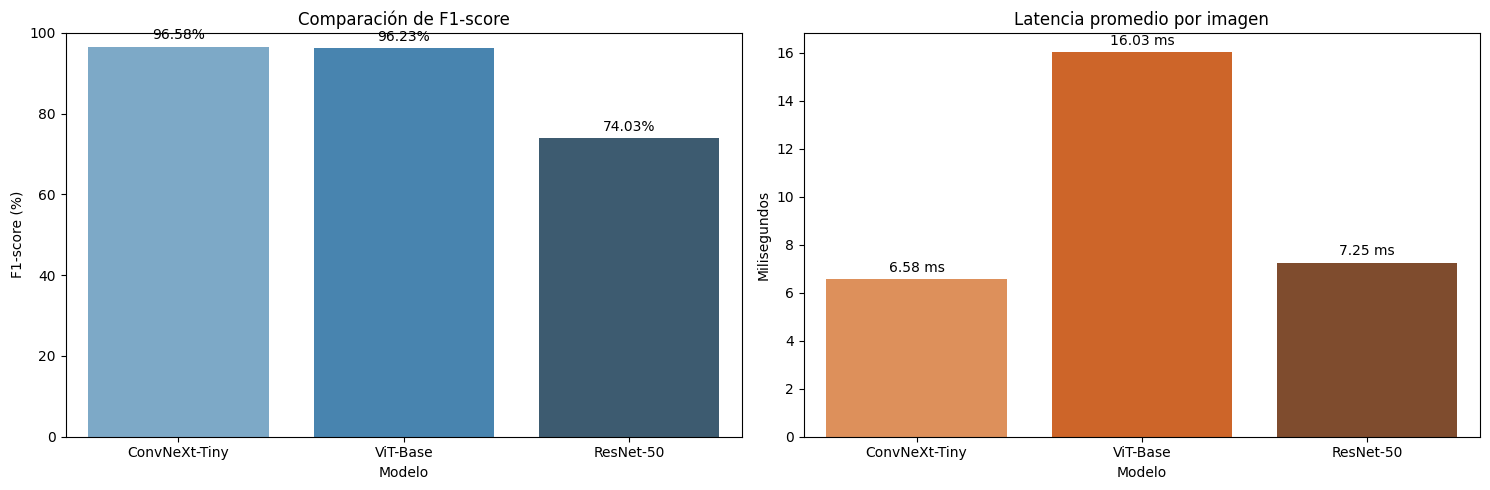

CONCLUSIÓN TÉCNICA
Se recomienda ConvNeXt-Tiny porque obtuvo el mayor F1-score (0.9658) y la menor latencia (6.58 ms por imagen) en una Tesla T4.

Archivos generados:
/content/resultados_comparacion_modelos.csv
/content/dataset_muestra_balanceada.csv


In [13]:
# COMPARACION FINAL GRAFICAS Y EXPORTACION DE RESULTADOS
tabla_resultados = pd.DataFrame(resultados_modelos)

tabla_resultados = tabla_resultados.sort_values(
    by="f1_score",
    ascending=False
).reset_index(drop=True)

tabla_resultados["accuracy_pct"] = tabla_resultados["accuracy"] * 100
tabla_resultados["precision_pct"] = tabla_resultados["precision"] * 100
tabla_resultados["recall_pct"] = tabla_resultados["recall"] * 100
tabla_resultados["f1_score_pct"] = tabla_resultados["f1_score"] * 100

display(
    tabla_resultados[
        [
            "modelo",
            "arquitectura",
            "parametros_millones",
            "accuracy_pct",
            "precision_pct",
            "recall_pct",
            "f1_score_pct",
            "latencia_ms"
        ]
    ].round(2)
)

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=tabla_resultados,
    x="modelo",
    y="f1_score_pct",
    hue="modelo",
    legend=False,
    ax=ejes[0],
    palette="Blues_d"
)

ejes[0].set_title("Comparación de F1-score")
ejes[0].set_xlabel("Modelo")
ejes[0].set_ylabel("F1-score (%)")
ejes[0].set_ylim(0, 100)

for contenedor in ejes[0].containers:
    ejes[0].bar_label(contenedor, fmt="%.2f%%", padding=3)

sns.barplot(
    data=tabla_resultados,
    x="modelo",
    y="latencia_ms",
    hue="modelo",
    legend=False,
    ax=ejes[1],
    palette="Oranges_d"
)

ejes[1].set_title("Latencia promedio por imagen")
ejes[1].set_xlabel("Modelo")
ejes[1].set_ylabel("Milisegundos")

for contenedor in ejes[1].containers:
    ejes[1].bar_label(contenedor, fmt="%.2f ms", padding=3)

plt.tight_layout()
plt.show()

# CSV de resultados comparativos
tabla_resultados.to_csv(
    "/content/resultados_comparacion_modelos.csv",
    index=False
)

# CSV de metadatos del dataset empleado
registros_dataset = []

for division, datos in dataset_modelado.items():
    for indice in range(len(datos)):
        imagen = datos[indice]["image"]

        registros_dataset.append({
            "split": division,
            "file_name": Path(imagen.filename).name,
            "label_id": datos[indice]["label"],
            "label": NOMBRES_CLASE[datos[indice]["label"]],
            "dataset_source": "2OBe/Ball_Screw_Drive_Classification"
        })

tabla_dataset = pd.DataFrame(registros_dataset)

tabla_dataset.to_csv(
    "/content/dataset_muestra_balanceada.csv",
    index=False
)

modelo_recomendado = tabla_resultados.iloc[0]

print("CONCLUSIÓN TÉCNICA")
print(
    f"Se recomienda {modelo_recomendado['modelo']} porque obtuvo el "
    f"mayor F1-score ({modelo_recomendado['f1_score']:.4f}) y la menor "
    f"latencia ({modelo_recomendado['latencia_ms']:.2f} ms por imagen) "
    f"en una Tesla T4."
)

print("\nArchivos generados:")
print("/content/resultados_comparacion_modelos.csv")
print("/content/dataset_muestra_balanceada.csv")